In [1]:
import pandas as pd


In [2]:
from datasets import load_dataset

dataset = load_dataset("scikit-learn/churn-prediction")
df = dataset["train"].to_pandas()
print(df.head())

c:\Users\itsaa\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies        Contract Pape

In [3]:
df_copy=df.copy()
df_copy.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# data cleaning

In [4]:
df_copy.describe()
df_copy.isnull().sum()
df_copy['SeniorCitizen'].value_counts()
df_copy[df_copy['StreamingMovies']==df_copy['StreamingTV']].value_counts()
streaming_services = []

for tv, movie in zip(df_copy['StreamingTV'], df_copy['StreamingMovies']):
    if tv == 'Yes' and movie == 'Yes':
        streaming_services.append('Both')
    elif tv == 'Yes' or movie == 'Yes':
        streaming_services.append('Single')
    else:
        streaming_services.append('None')

df_copy['StreamingServices'] = streaming_services
df_copy.drop(['customerID','PhoneService','StreamingTV','StreamingMovies','TotalCharges'],inplace=True,axis=1)

In [5]:
df_copy.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,Churn,StreamingServices
0,Female,0,Yes,No,1,No phone service,DSL,No,Yes,No,No,Month-to-month,Yes,Electronic check,29.85,No,None
1,Male,0,No,No,34,No,DSL,Yes,No,Yes,No,One year,No,Mailed check,56.95,No,None
2,Male,0,No,No,2,No,DSL,Yes,Yes,No,No,Month-to-month,Yes,Mailed check,53.85,Yes,None
3,Male,0,No,No,45,No phone service,DSL,Yes,No,Yes,Yes,One year,No,Bank transfer (automatic),42.30,No,None
4,Female,0,No,No,2,No,Fiber optic,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,Yes,None


# EDA

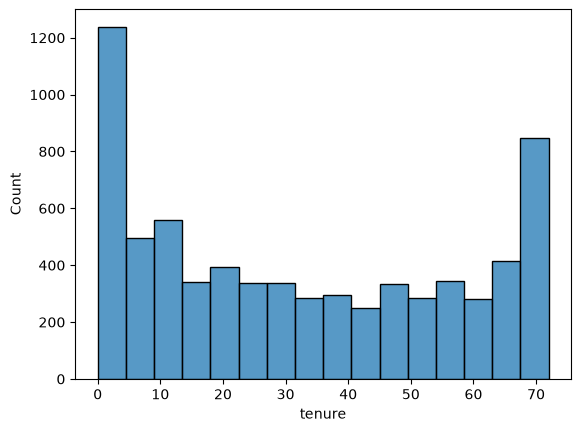

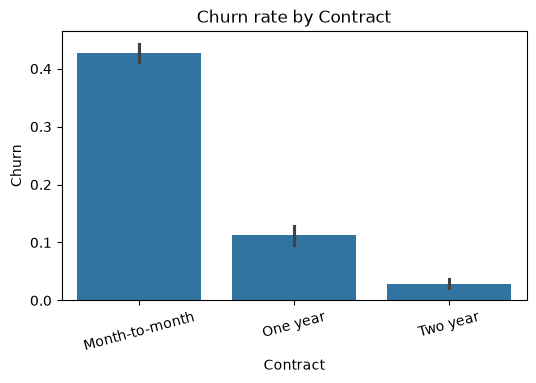

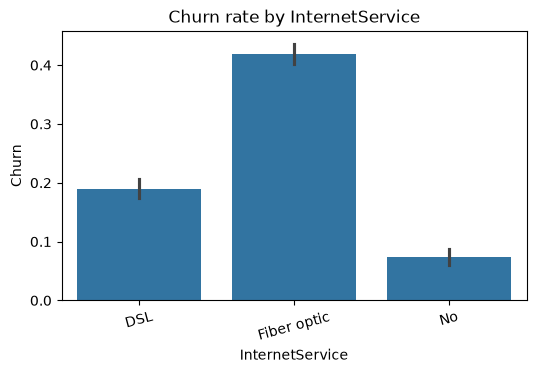

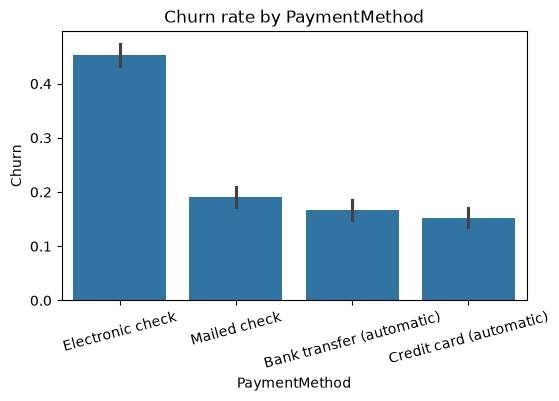

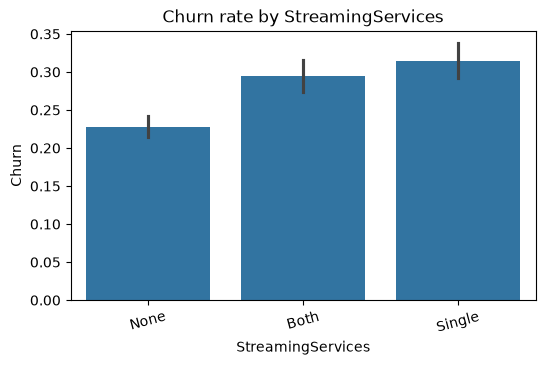

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt
sns.histplot(df_copy['tenure'])
df_copy['Churn'].value_counts()#class imbalance detected
cat_features=['Contract','InternetService','PaymentMethod','StreamingServices']
df_copy['Churn']=df_copy['Churn'].map({'Yes':1,'No':0})
for cat in cat_features:
    plt.figure(figsize=(6,3.5))
    sns.barplot(x=df_copy[cat],y=df_copy['Churn'])
    plt.title(f'Churn rate by {cat}')
    plt.xticks(rotation=15)
    plt.show()



# preprocessing

In [7]:
df_copy['TechSupport'].value_counts()

TechSupport
No                     3473
Yes                    2044
No internet service    1526
Name: count, dtype: int64

In [8]:
df_copy.head()
lab_col=['gender','Partner','Dependents','PaperlessBilling']
onehot_col=['MultipleLines','InternetService','OnlineSecurity','OnlineBackup',
            'DeviceProtection','TechSupport','Contract','PaymentMethod','StreamingServices']

# train_test split

In [9]:
from sklearn.model_selection import train_test_split
X=df_copy.drop('Churn',axis=1)
y=df_copy['Churn']
x_train,x_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

# column transformation

In [10]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder,OneHotEncoder
preprocessor=ColumnTransformer(transformers=[('label_encoder',OrdinalEncoder(),lab_col),
                                             ('OneHot_encoder',OneHotEncoder(handle_unknown='ignore'),onehot_col),
                                             ],remainder='passthrough')



# training model (XG Boost)

In [11]:
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
neg_count=(y_train==0).sum()
pos_count=(y_train==1).sum()
scale_weight=neg_count/pos_count
pipeline=Pipeline(steps=[('preprocessor',preprocessor),
                         ('classifier',XGBClassifier(n_estimators=200,max_depth=4,
                                                     learning_rate=0.05,scale_pos_weight=scale_weight,
                                                     eval_metric='logloss',random_state=42)),
                         ])
pipeline.fit(x_train,y_train)





,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](16,)","['gender','SeniorCitizen','Partner',...,'PaymentMethod','MonthlyCharges', 'StreamingServices']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,16
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('label_encoder', ...), ('OneHot_encoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``

In [13]:
from sklearn.metrics import classification_report,roc_auc_score
import joblib
y_pred = pipeline.predict(x_test)
y_prob = pipeline.predict_proba(x_test)[:, 1]

print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))
joblib.dump(pipeline, 'churn_pipeline.pkl')

ROC-AUC Score: 0.8406

Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.74      0.81      1035
           1       0.51      0.77      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.79      0.74      0.76      1409



['churn_pipeline.pkl']

In [14]:
df_copy.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,Churn,StreamingServices
0,Female,0,Yes,No,1,No phone service,DSL,No,Yes,No,No,Month-to-month,Yes,Electronic check,29.85,0,None
1,Male,0,No,No,34,No,DSL,Yes,No,Yes,No,One year,No,Mailed check,56.95,0,None
2,Male,0,No,No,2,No,DSL,Yes,Yes,No,No,Month-to-month,Yes,Mailed check,53.85,1,None
3,Male,0,No,No,45,No phone service,DSL,Yes,No,Yes,Yes,One year,No,Bank transfer (automatic),42.30,0,None
4,Female,0,No,No,2,No,Fiber optic,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,1,None
